In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings('ignore')

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
import os

print(os.listdir())

['.anaconda', '.arduinoIDE', '.conda', '.condarc', '.continuum', '.dacfx', '.ipynb_checkpoints', '.ipython', '.jupyter', '.matplotlib', '.pencil', '2025_11_30_13_01_04_IMG_0249.JPG', '2025_11_30_13_01_04_IMG_0249.MOV', '2025_11_30_13_01_05_IMG_0250.JPG', '2025_11_30_13_01_05_IMG_0250.MOV', '2025_11_30_13_01_25_IMG_0251.JPG', '2025_11_30_13_01_25_IMG_0251.MOV', '2025_11_30_13_01_36_IMG_0252.JPG', '2025_11_30_13_01_36_IMG_0252.MOV', '2025_11_30_13_01_39_IMG_0253.JPG', '2025_11_30_13_01_39_IMG_0253.MOV', '2025_11_30_13_57_20_IMG_0256.JPG', '2025_11_30_13_57_20_IMG_0256.MOV', '2025_11_30_13_57_23_IMG_0257.JPG', '2025_11_30_13_57_23_IMG_0257.MOV', '2025_11_30_13_59_21_IMG_0258.JPG', '2025_11_30_13_59_21_IMG_0258.MOV', '2025_11_30_14_01_46_IMG_0270.JPG', '2025_11_30_14_01_46_IMG_0270.MOV', '2025_11_30_14_01_49_IMG_0271.JPG', '2025_11_30_14_01_49_IMG_0271.MOV', '2025_11_30_14_01_51_IMG_0272.JPG', '2025_11_30_14_01_51_IMG_0272.MOV', '2025_11_30_14_01_53_IMG_0273.JPG', '2025_11_30_14_01_53_IMG_

In [3]:
df = pd.read_csv("Preprocessed_Superstore_Central.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Standard_Discount,Standard_Profit,Label_Segment,Category_Furniture,Category_Office Supplies,Category_Technology,ShipMode_First Class,ShipMode_Same Day,ShipMode_Second Class,ShipMode_Standard Class
0,7981,CA-2011-103800,2013-01-03,2013-01-07,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,-0.152060,-0.039604,0,0,1,0,0,0,0,1
1,740,CA-2011-112326,2013-01-04,2013-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,-0.152060,-0.043994,2,0,1,0,0,0,0,1
2,741,CA-2011-112326,2013-01-04,2013-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,-0.152060,-0.280922,2,0,1,0,0,0,0,1
3,742,CA-2011-112326,2013-01-04,2013-01-08,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,2.108882,-0.077480,2,0,1,0,0,0,0,1
4,7661,CA-2011-105417,2013-01-07,2013-01-12,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,1.355235,-0.242952,0,1,0,0,0,0,0,1


In [4]:
print("Dataset Shape:", df.shape)

Dataset Shape: (2323, 37)


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2323 entries, 0 to 2322
Data columns (total 37 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Row ID                    2323 non-null   int64  
 1   Order ID                  2323 non-null   object 
 2   Order Date                2323 non-null   object 
 3   Ship Date                 2323 non-null   object 
 4   Ship Mode                 2323 non-null   object 
 5   Customer ID               2323 non-null   object 
 6   Customer Name             2323 non-null   object 
 7   Segment                   2323 non-null   object 
 8   Country                   2323 non-null   object 
 9   City                      2323 non-null   object 
 10  State                     2323 non-null   object 
 11  Postal Code               2323 non-null   int64  
 12  Region                    2323 non-null   object 
 13  Product ID                2323 non-null   object 
 14  Category

In [6]:
print("Duplicate Rows:", df.duplicated().sum())

Duplicate Rows: 0


In [7]:
print("Missing Values:")
print(df.isnull().sum().sum())

Missing Values:
0


In [8]:
df['Order Date'] = pd.to_datetime(df['Order Date'])
df['Ship Date'] = pd.to_datetime(df['Ship Date'])

print(df[['Order Date', 'Ship Date']].dtypes)

Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [9]:
total_sales = df['Sales'].sum()
total_profit = df['Profit'].sum()
total_orders = df['Order ID'].nunique()

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)

Total Sales: 501239.89
Total Profit: 39706.36
Total Orders: 1175


In [10]:
category_analysis = df.groupby('Category').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Quantity': 'sum'
}).reset_index()

category_analysis

,Category,Sales,Profit,Quantity
0,Furniture,163797.1638,-2871.0494,1827
1,Office Supplies,167026.4150,8879.9799,5409
2,Technology,170416.3120,33697.4320,1544


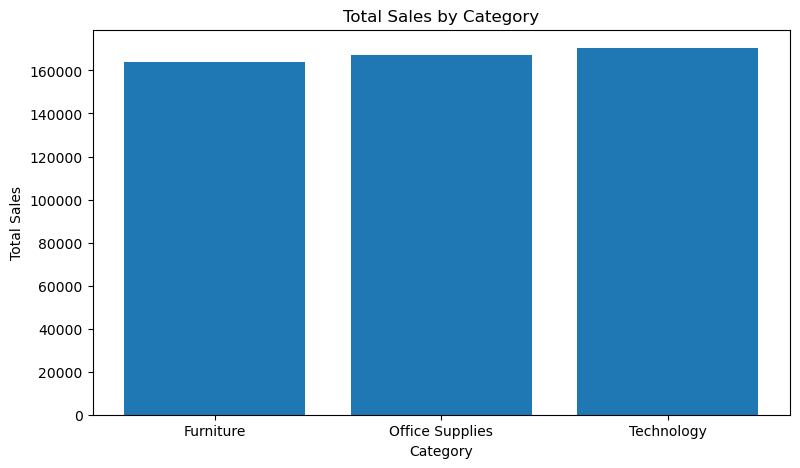

In [11]:
plt.figure(figsize=(9,5))

plt.bar(
    category_analysis['Category'],
    category_analysis['Sales']
)

plt.title('Total Sales by Category')
plt.xlabel('Category')
plt.ylabel('Total Sales')

plt.show()

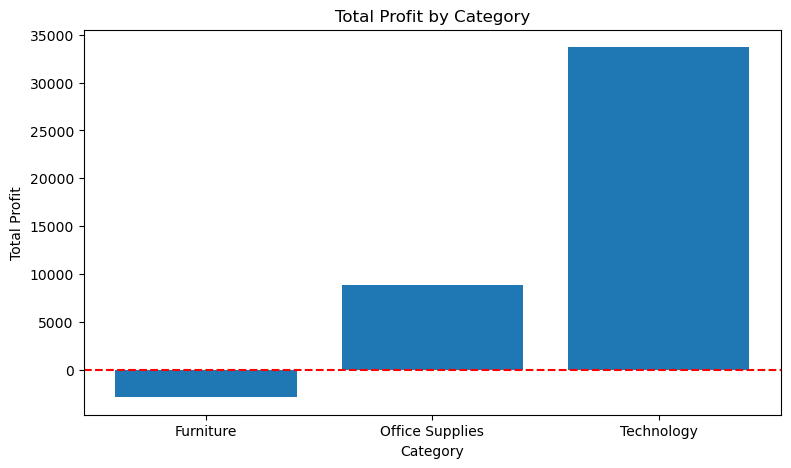

In [12]:
plt.figure(figsize=(9,5))

plt.bar(
    category_analysis['Category'],
    category_analysis['Profit']
)

plt.title('Total Profit by Category')
plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.axhline(y=0, color='red', linestyle='--')

plt.show()

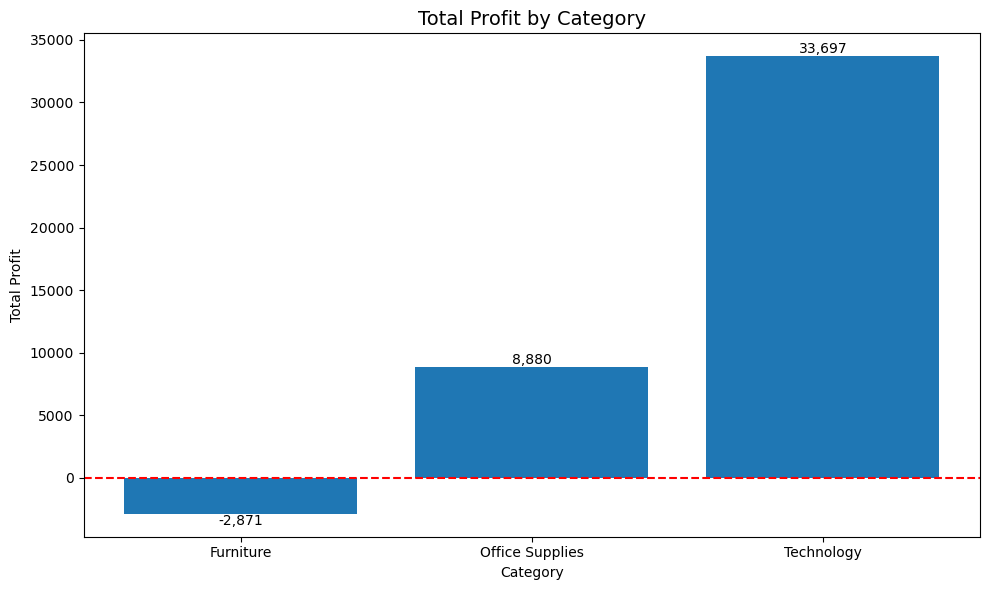

In [13]:
plt.figure(figsize=(10, 6))

bars = plt.bar(
    category_analysis['Category'],
    category_analysis['Profit']
)

plt.title('Total Profit by Category', fontsize=14)
plt.xlabel('Category')
plt.ylabel('Total Profit')

plt.axhline(y=0, color='red', linestyle='--')

for bar in bars:
    value = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        value,
        f'{value:,.0f}',
        ha='center',
        va='bottom' if value >= 0 else 'top'
    )

plt.tight_layout()
plt.show()

In [14]:
df['Year_Month'] = df['Order Date'].dt.to_period('M')

monthly_sales = df.groupby('Year_Month')['Sales'].sum().reset_index()

monthly_sales['Year_Month'] = monthly_sales['Year_Month'].astype(str)

monthly_sales.head()

,Year_Month,Sales
0,2013-01,1539.906
1,2013-02,1233.174
2,2013-03,5827.602
3,2013-04,3712.340
4,2013-05,4048.506


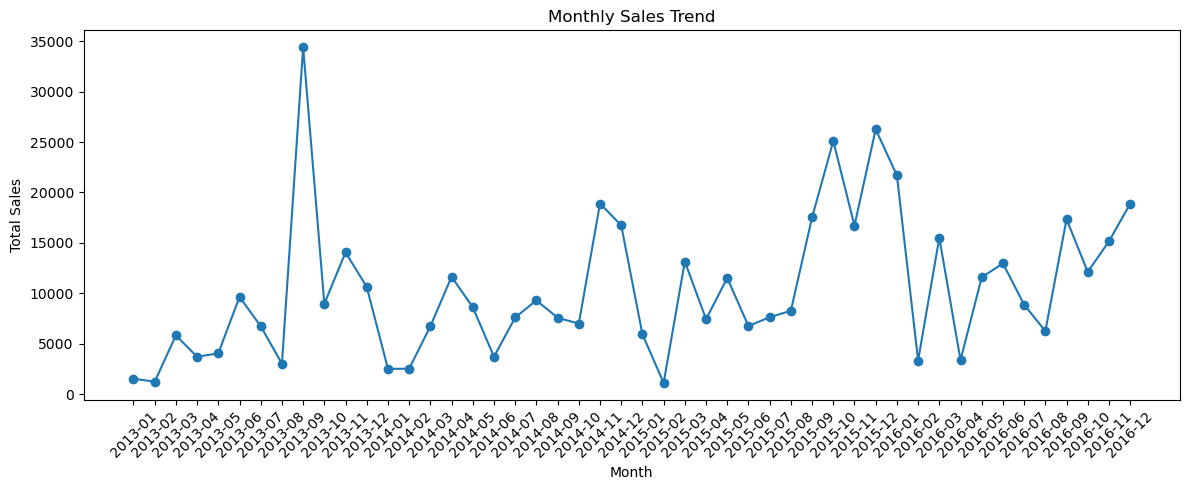

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales['Year_Month'],
    monthly_sales['Sales'],
    marker='o'
)

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [16]:
highest_month = monthly_sales.loc[monthly_sales['Sales'].idxmax()]

lowest_month = monthly_sales.loc[monthly_sales['Sales'].idxmin()]

print("Highest Sales Month:")
print(highest_month)

print("\nLowest Sales Month:")
print(lowest_month)

Highest Sales Month:
Year_Month       2013-09
Sales         34408.6898
Name: 8, dtype: object

Lowest Sales Month:
Year_Month     2015-02
Sales         1115.728
Name: 25, dtype: object


In [17]:
region_analysis = df.groupby('Region').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).reset_index()

region_analysis

,Region,Sales,Profit
0,Central,501239.8908,39706.3625


In [18]:
print(df['Region'].unique())

['Central']


In [19]:
print(df['Region'].value_counts())

Region
Central    2323
Name: count, dtype: int64


In [20]:
import os

files = [f for f in os.listdir() if 'center' in f.lower() or 'super' in f.lower()]

print(files)

['Preprocessed_Superstore_Central.csv']


In [22]:
import os
print([f for f in os.listdir() if f.endswith(('.csv', '.xlsx', '.xls'))])

['Central_Superstore.xlsx', 'Preprocessed_Superstore_Central.csv']


In [23]:
df_full = pd.read_excel('Central_Superstore.xlsx')

print("Shape:", df_full.shape)
print("\nRegions:")
print(df_full['Region'].value_counts())

Shape: (2323, 21)

Regions:
Region
Central    2323
Name: count, dtype: int64


In [24]:
print(df_full.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [25]:
print("Missing Values:")
print(df_full.isnull().sum())

Missing Values:
Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64


In [26]:
print("\nDuplicated Rows:")
print(df_full.duplicated().sum())


Duplicated Rows:
0


In [27]:
df_full['Order Date'] = pd.to_datetime(df_full['Order Date'])
df_full['Ship Date'] = pd.to_datetime(df_full['Ship Date'])

In [28]:
df_full.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2323 entries, 0 to 2322
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         2323 non-null   int64         
 1   Order ID       2323 non-null   object        
 2   Order Date     2323 non-null   datetime64[ns]
 3   Ship Date      2323 non-null   datetime64[ns]
 4   Ship Mode      2323 non-null   object        
 5   Customer ID    2323 non-null   object        
 6   Customer Name  2323 non-null   object        
 7   Segment        2323 non-null   object        
 8   Country        2323 non-null   object        
 9   City           2323 non-null   object        
 10  State          2323 non-null   object        
 11  Postal Code    2323 non-null   int64         
 12  Region         2323 non-null   object        
 13  Product ID     2323 non-null   object        
 14  Category       2323 non-null   object        
 15  Sub-Category   2323 n

In [29]:
print("Duplicated Rows:")
print(df_full.duplicated().sum())

print("\nTotal Missing Values:")
print(df_full.isnull().sum().sum())

Duplicated Rows:
0

Total Missing Values:
0


In [30]:
total_sales = df_full['Sales'].sum()
total_profit = df_full['Profit'].sum()
total_orders = df_full['Order ID'].nunique()
total_quantity = df_full['Quantity'].sum()

profit_margin = (total_profit / total_sales) * 100

print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Quantity:", total_quantity)
print("Profit Margin:", round(profit_margin, 2), "%")

Total Sales: 501239.89
Total Profit: 39706.36
Total Orders: 1175
Total Quantity: 8780
Profit Margin: 7.92 %


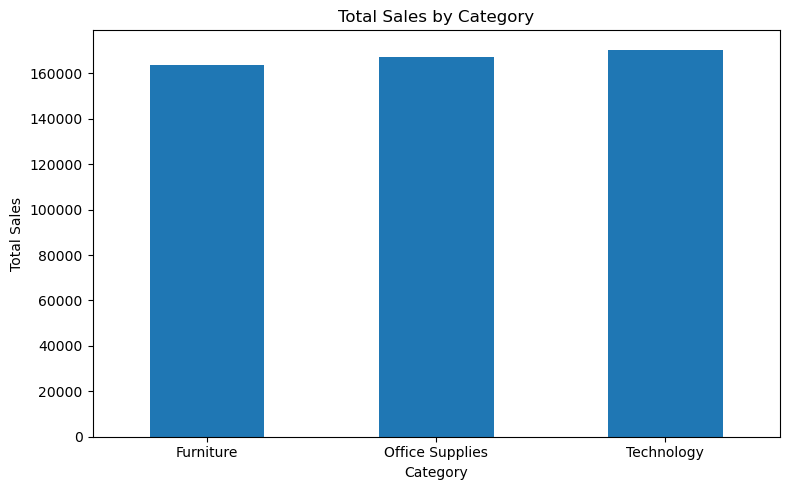

In [31]:
import matplotlib.pyplot as plt

category_sales = df_full.groupby('Category')['Sales'].sum()

category_sales.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Sales by Category'
)

plt.xlabel('Category')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

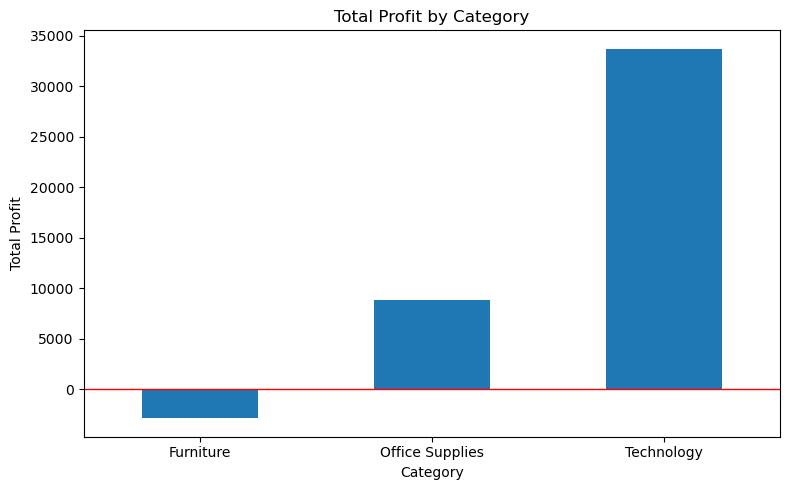

In [32]:
category_profit = df_full.groupby('Category')['Profit'].sum()

category_profit.plot(
    kind='bar',
    figsize=(8, 5),
    title='Total Profit by Category'
)

plt.axhline(y=0, color='red', linewidth=1)
plt.xlabel('Category')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [33]:
discount_analysis = df_full.groupby('Discount').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).reset_index()

discount_analysis

,Discount,Sales,Profit,Order ID
0,0.00,243150.6400,76125.4407,410
1,0.10,7735.1040,1918.1651,18
2,0.20,121220.0480,14055.0311,550
3,0.30,64935.2900,-6540.8542,137
4,0.32,14493.4588,-2391.1377,27
5,0.40,19546.2240,-2666.8434,12
6,0.50,6550.6700,-4309.7447,17
7,0.60,6644.7000,-5944.6552,127
8,0.80,16963.7560,-30539.0392,250


In [34]:
discount_analysis['Profit Margin'] = (
    discount_analysis['Profit'] /
    discount_analysis['Sales']
) * 100

discount_analysis

,Discount,Sales,Profit,Order ID,Profit Margin
0,0.00,243150.6400,76125.4407,410,31.307934
1,0.10,7735.1040,1918.1651,18,24.798181
2,0.20,121220.0480,14055.0311,550,11.594642
3,0.30,64935.2900,-6540.8542,137,-10.072881
4,0.32,14493.4588,-2391.1377,27,-16.498047
5,0.40,19546.2240,-2666.8434,12,-13.643778
6,0.50,6550.6700,-4309.7447,17,-65.790899
7,0.60,6644.7000,-5944.6552,127,-89.464614
8,0.80,16963.7560,-30539.0392,250,-180.025221


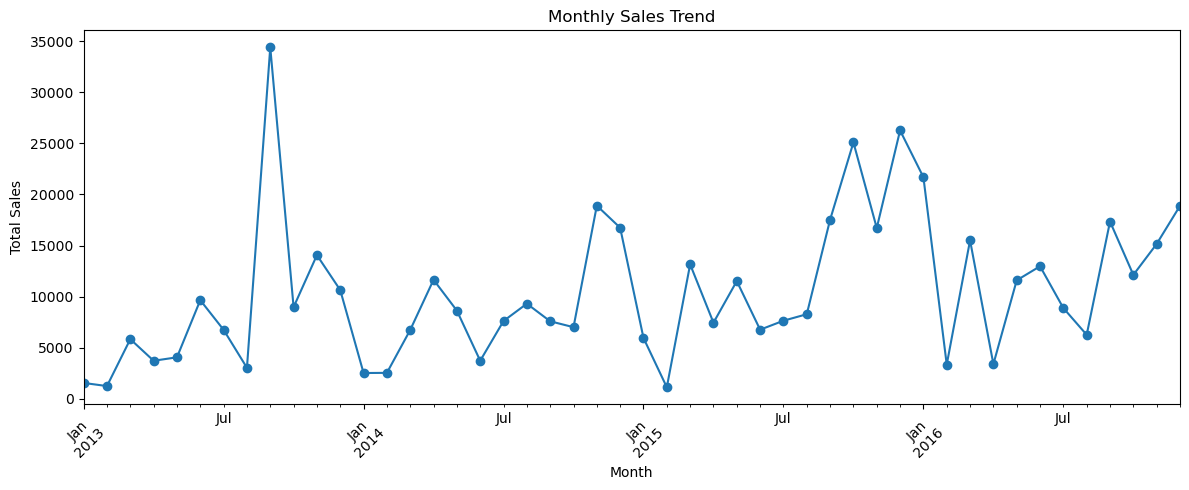

In [35]:
df_full['Year_Month'] = df_full['Order Date'].dt.to_period('M')

monthly_sales = df_full.groupby('Year_Month')['Sales'].sum()

monthly_sales.plot(
    figsize=(12, 5),
    marker='o',
    title='Monthly Sales Trend'
)

plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [36]:
segment_analysis = df_full.groupby('Segment').agg({
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique',
    'Customer ID': 'nunique'
}).reset_index()

segment_analysis

,Segment,Sales,Profit,Order ID,Customer ID
0,Consumer,252031.4340,8564.0481,604,328
1,Corporate,157995.8128,18703.9020,348,180
2,Home Office,91212.6440,12438.4124,223,121


In [37]:
top_products = df_full.groupby('Product Name').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).sort_values(
    by='Sales',
    ascending=False
).head(10)

top_products

,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,17499.950,8399.9760
Lexmark MX611dhe Monochrome Laser Printer,14279.916,-1189.9930
Ibico EPK-21 Electric Binding System,11339.940,1700.9910
GBC Ibimaster 500 Manual ProClick Binding System,10653.720,3804.9000
GBC DocuBind P400 Electric Binding System,8710.336,-3048.6176
HON 5400 Series Task Chairs for Big and Tall,6939.702,210.2940
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,6100.752,-1525.1880
Canon PC1060 Personal Laser Copier,4899.930,2302.9671
Mitel MiVoice 5330e IP Phone,4179.848,516.9812


In [38]:
state_analysis = df_full.groupby('State').agg({
    'Sales': 'sum',
    'Profit': 'sum'
}).sort_values(
    by='Sales',
    ascending=False
)

state_analysis

,Sales,Profit
State,,
Texas,170188.0458,-25729.3563
Illinois,80166.1010,-12607.8870
Michigan,76269.6140,24463.1876
Indiana,53555.3600,18382.9363
Wisconsin,32114.6100,8401.8004
Minnesota,29863.1500,10823.1874
Missouri,22205.1500,6436.2105
Oklahoma,19683.3900,4853.9560
Nebraska,7464.9300,2037.0942


In [39]:
df_full['Shipping Days'] = (
    df_full['Ship Date'] - df_full['Order Date']
).dt.days

shipping_analysis = df_full.groupby('Ship Mode').agg({
    'Shipping Days': 'mean',
    'Sales': 'sum',
    'Profit': 'sum',
    'Order ID': 'nunique'
}).round(2).reset_index()

shipping_analysis

,Ship Mode,Shipping Days,Sales,Profit,Order ID
0,First Class,2.32,58746.92,3707.27,174
1,Same Day,0.03,20415.41,1531.88,62
2,Second Class,3.33,103550.01,9114.83,224
3,Standard Class,4.99,318527.56,25352.38,715
